Kullanılan cihaz: cuda

######################################################

Model: e5

-> Kombinasyon: s
Epoch 5/20 - Loss: 0.9325
Epoch 10/20 - Loss: 0.4848
Epoch 15/20 - Loss: 0.2769
Epoch 20/20 - Loss: 0.2028
F1 Skoru: 0.2677 | Accuracy: 0.3969

-> Kombinasyon: g
Epoch 5/20 - Loss: 0.9747
Epoch 10/20 - Loss: 0.5875
Epoch 15/20 - Loss: 0.3198
Epoch 20/20 - Loss: 0.2220
F1 Skoru: 0.2731 | Accuracy: 0.4293

-> Kombinasyon: d
Epoch 5/20 - Loss: 0.9358
Epoch 10/20 - Loss: 0.5400
Epoch 15/20 - Loss: 0.3003
Epoch 20/20 - Loss: 0.1919
F1 Skoru: 0.3005 | Accuracy: 0.4386

-> Kombinasyon: s-g
Epoch 5/20 - Loss: 0.8893
Epoch 10/20 - Loss: 0.3918
Epoch 15/20 - Loss: 0.1912
Epoch 20/20 - Loss: 0.1246
F1 Skoru: 0.2936 | Accuracy: 0.4232

-> Kombinasyon: |s-g|
Epoch 5/20 - Loss: 0.5515
Epoch 10/20 - Loss: 0.1576
Epoch 15/20 - Loss: 0.0793
Epoch 20/20 - Loss: 0.0692
F1 Skoru: 0.2722 | Accuracy: 0.4354

-> Kombinasyon: s-d
Epoch 5/20 - Loss: 0.8423
Epoch 10/20 - Loss: 0.3384
Epoch 15/20 - Loss: 

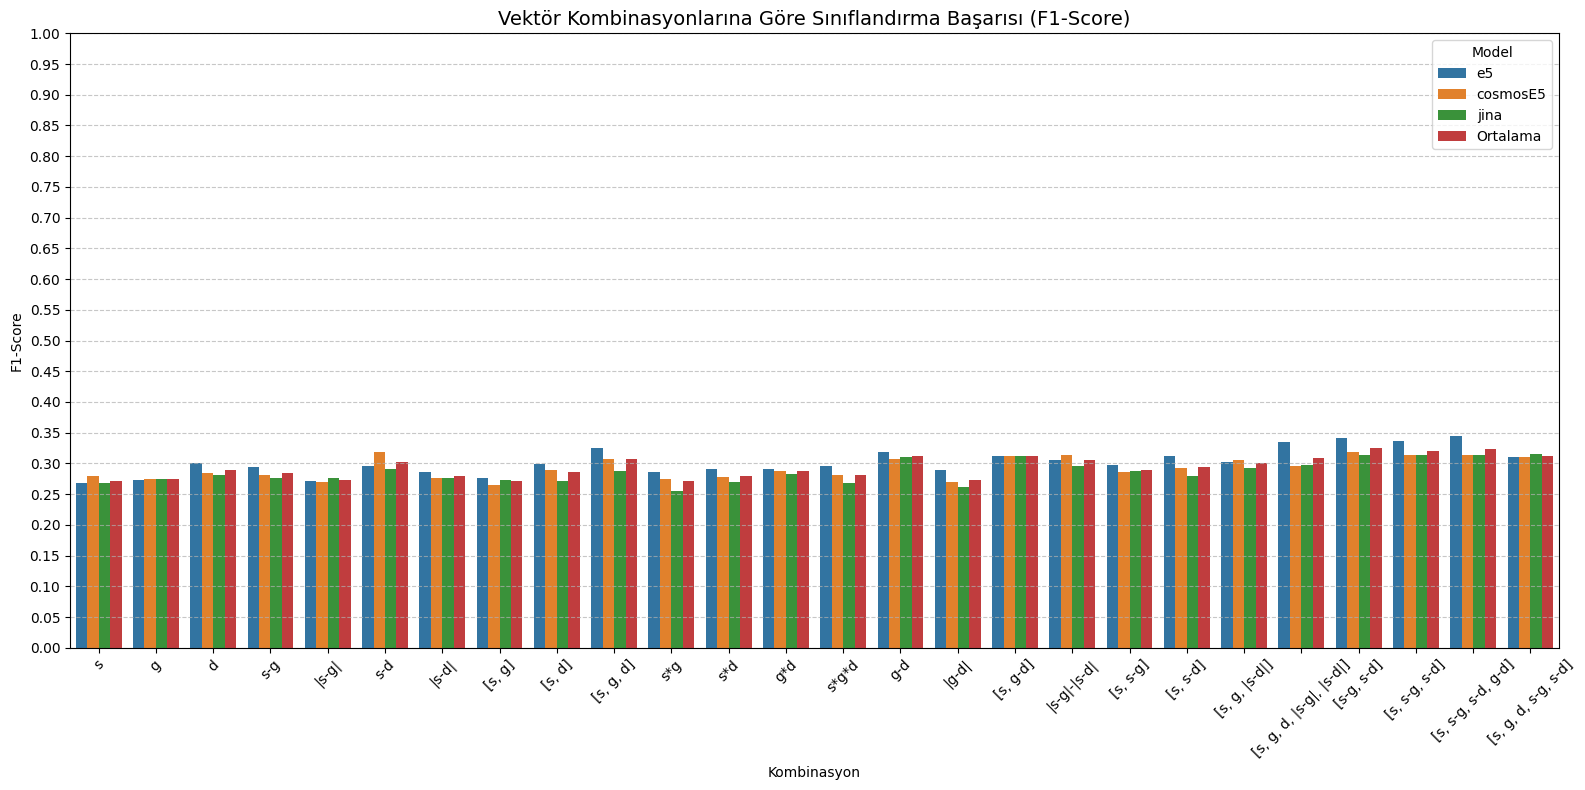

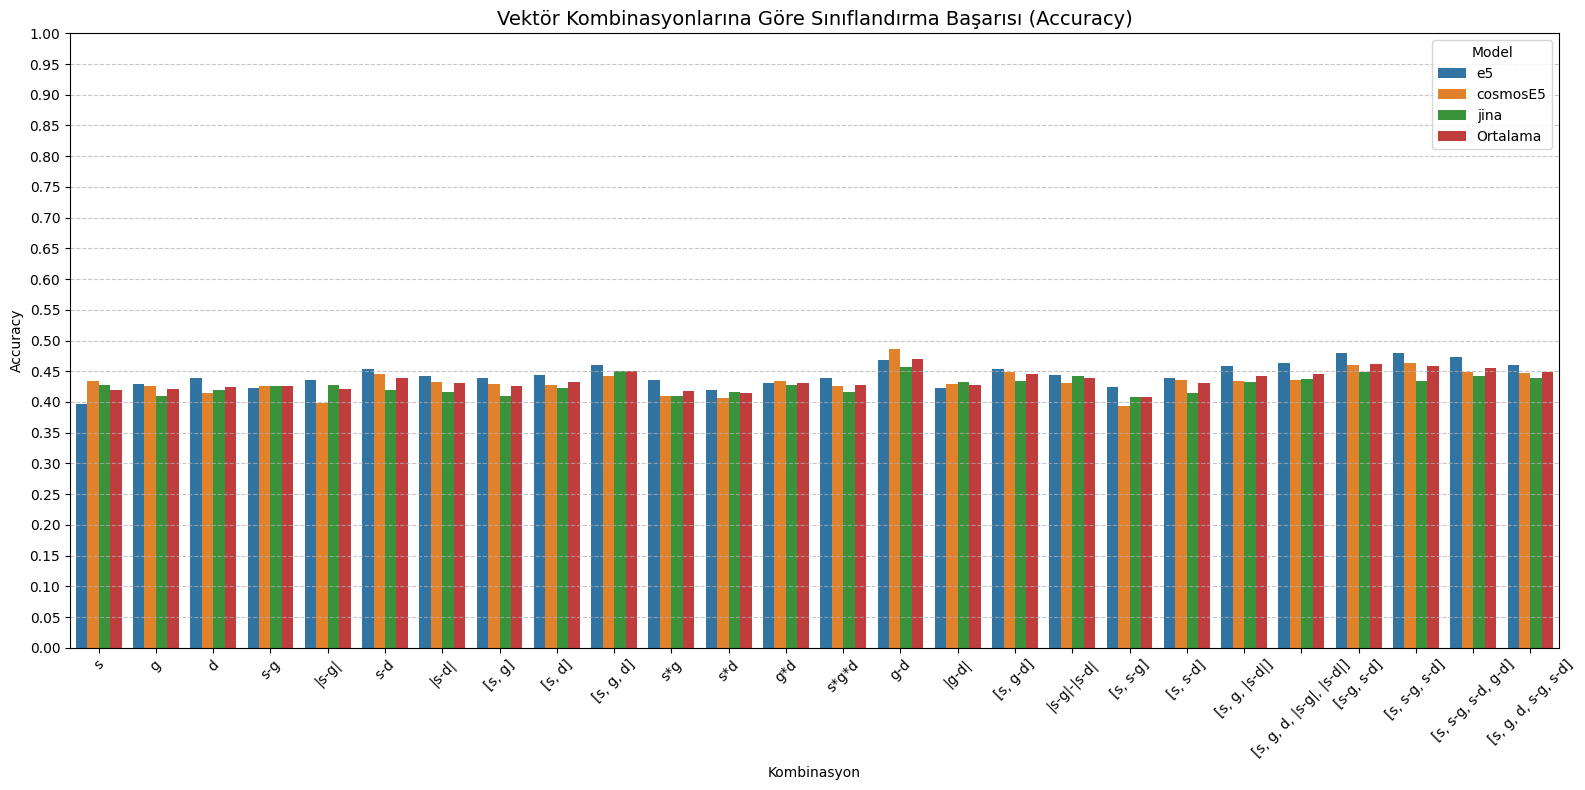

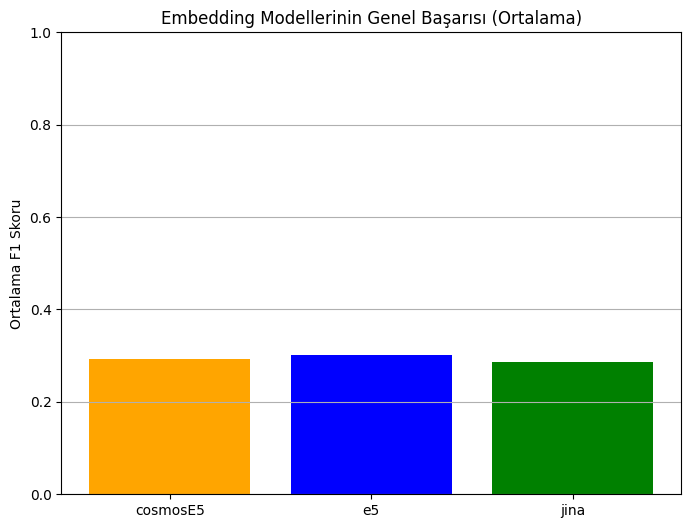

In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
import seaborn as sns

# Uygun GPU varsa kullanılır.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Kullanılan cihaz: {device}")

# Veri yüklenir.
file = "13k"
path = f"drive/MyDrive/Colab Notebooks/embeddings/{file}"
models = ['e5', 'cosmosE5', 'jina']

df = pd.read_excel(f"{file}.xlsx")
df.columns = ['soru', 'gpt4o', 'deepseek', 'etiket']
y = torch.tensor(df['etiket'].values) - 1  # Etiketleri 0-3 aralığına çek

# Model parametreleri ayarlanır.
batch_size = 128
epochs = 20
learning_rate = 0.001

# Kombinasyonları oluşturur.
def get_combs(s, g, d):
    return {
        "s": s,
        "g": g,
        "d": d,
        "s-g": s - g,
        "|s-g|": torch.abs(s - g),
        "s-d": s - d,
        "|s-d|":  torch.abs(s - d),
        "[s, g]":  torch.cat([s, g], dim=1),
        "[s, d]":  torch.cat([s, d], dim=1),
        "[s, g, d]":  torch.cat([s, g, d], dim=1),
        "s*g":  s * g,
        "s*d":  s * d,
        "g*d":  g * d,
        "s*g*d":  s * g * d,
        "g-d":  g - d,
        "|g-d|":  torch.abs(g - d),
        "[s, g-d]":  torch.cat([s, g - d], dim=1),
        "|s-g|-|s-d|": torch.abs(s - g) - torch.abs(s - d),
        "[s, s-g]":  torch.cat([s, s - g], dim=1),
        "[s, s-d]":  torch.cat([s, s - d], dim=1),
        "[s, g, |s-d|]":  torch.cat([s, g, torch.abs(s - d)], dim=1),
        "[s, g, d, |s-g|, |s-d|]":  torch.cat([s, g, d, torch.abs(s - g), torch.abs(s - d)], dim=1),
        "[s-g, s-d]":  torch.cat([s - g, s - d], dim=1),
        "[s, s-g, s-d]":  torch.cat([s, s - g, s - d], dim=1),
        "[s, s-g, s-d, g-d]":  torch.cat([s, s - g, s - d, g - d], dim=1),
        "[s, g, d, s-g, s-d]":  torch.cat([s, g, d, s - g, s - d], dim=1)
    }

# MLP Modeli
class OptimizedMLP(nn.Module):
    def __init__(self, input_dim, num_classes=4):
        super(OptimizedMLP, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.ReLU(),
            nn.Dropout(0.15),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.15),
            nn.Linear(256, num_classes)
        )
    def forward(self, x):
        return self.model(x)

results = []

# Her model eğitilir ve test edilir.
for model_name in models:
    print("\n######################################################\n")
    print(f"Model: {model_name}")

    s = torch.load(f"{path}_{model_name}_questions.pt").to(device)
    g = torch.load(f"{path}_{model_name}_gpt4o.pt").to(device)
    d = torch.load(f"{path}_{model_name}_deepseek.pt").to(device)

    # Her modelin s, g, d vektörlerine göre kombinasyonlar oluşturulur.
    combs = get_combs(s, g, d)

    # Her kombinasyon modele girdi olarak verilir.
    for name, X in combs.items():
        print(f"\n-> Kombinasyon: {name}")

        # Vektörler standartlaştırılır. (Bu şekilde daha yüksek başarı oranları elde edilmektedir.)
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X.cpu().numpy())
        X = torch.tensor(X_scaled, dtype=torch.float32).to(device)

        # Her kombinasyon aynı şekilde test, train kümesine ayrılır.
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=34)
        train_dataset = TensorDataset(X_train, y_train)
        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

        # MLP modeli, Loss fonksiyonu ve optimizer tanımlanır.
        model = OptimizedMLP(input_dim=X.shape[1]).to(device)
        criterion = nn.CrossEntropyLoss()
        optimizer = optim.Adam(model.parameters(), lr=learning_rate)

        # Model, belirlenen epoch sayısı kadar eğitilir.
        for epoch in range(epochs):
            model.train()
            total_loss = 0
            for batch_X, batch_y in train_loader:
                optimizer.zero_grad()
                outputs = model(batch_X)
                loss = criterion(outputs, batch_y.to(device))
                loss.backward()
                optimizer.step()
                total_loss += loss.item()
            avg_loss = total_loss / len(train_loader)
            if (epoch+1) % 5 == 0:
              print(f"Epoch {epoch+1}/{epochs} - Loss: {avg_loss:.4f}")

        # Eğitim tamamlandıktan sonra model test verisi üzerinde değerlendirilir.
        model.eval()
        with torch.no_grad():
            preds = model(X_test)
            y_pred = torch.argmax(preds, dim=1).cpu().numpy()
            f1 = f1_score(y_test.cpu().numpy(), y_pred, average='macro')
            acc = accuracy_score(y_test.cpu().numpy(), y_pred)

        print(f"F1 Skoru: {f1:.4f} | Accuracy: {acc:.4f}")
        results.append([model_name, name, f1, acc])


##################
# Görselleştirme #
##################

df_results = pd.DataFrame(results, columns=['Model', 'Kombinasyon', 'F1', 'Accuracy'])

# Her kombinasyon için ortalama F1 skoru hesaplanır.
df_mean = df_results.groupby('Kombinasyon')['F1'].mean().reset_index()
df_mean['Model'] = 'Ortalama'
df_plot = pd.concat([df_results, df_mean], ignore_index=True)

plt.figure(figsize=(16,8))
sns.barplot(data=df_plot, x='Kombinasyon', y='F1', hue='Model')
plt.title("Vektör Kombinasyonlarına Göre Sınıflandırma Başarısı (F1-Score)", fontsize=14)
plt.ylabel("F1-Score")
plt.ylim(0, 1)
plt.yticks(np.arange(0, 1.05, 0.05))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title="Model")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Her kombinasyon için ortalama doğruluk hesaplanır.
df_mean = df_results.groupby('Kombinasyon')['Accuracy'].mean().reset_index()
df_mean['Model'] = 'Ortalama'
df_plot = pd.concat([df_results, df_mean], ignore_index=True)

plt.figure(figsize=(16,8))
sns.barplot(data=df_plot, x='Kombinasyon', y='Accuracy', hue='Model')
plt.title("Vektör Kombinasyonlarına Göre Sınıflandırma Başarısı (Accuracy)", fontsize=14)
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.yticks(np.arange(0, 1.05, 0.05))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title="Model")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Embedding modellerinin ortalama başarısı hesaplanır.
df_avg = df_results.groupby('Model')['F1'].mean().reset_index()

plt.figure(figsize=(8,6))
plt.bar(df_avg['Model'], df_avg['F1'], color=['orange', 'blue', 'green'])
plt.ylabel("Ortalama F1 Skoru")
plt.title("Embedding Modellerinin Genel Başarısı (Ortalama)")
plt.ylim(0,1)
plt.grid(axis='y')
plt.show()